# 05 — Pre-integration Preprocessing and Clustering

Starting from the doublet-scored object, this notebook:
1. Loads the QC-passed, doublet-scored object (doublets retained for cluster-level assessment)
2. Preprocesses all cells: normalisation, log-transform, HVG selection, PCA, neighbours, UMAP
3. Runs Leiden clustering and explores the effect of resolution

---
## Step 0 — Imports

In [1]:
%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path

import os
import scipy.io
import scanpy as sc
import anndata as ad
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

sc.settings.verbosity = 2  # show INFO messages from scanpy
sc.settings.set_figure_params(dpi=100, facecolor="white")

print(f"scanpy  version: {sc.__version__}")
print(f"anndata version: {ad.__version__}")
print(f"pandas  version: {pd.__version__}")
print(f"numpy   version: {np.__version__}")

from besca_sc import lognorm
from besca_sc.paths import (
    EXTERNAL_DIR,
    INTERIM_DIR,
    PROCESSED_DIR,
    RAW_DIR,
    RESULTS_DIR,
)

scanpy  version: 1.12.4
anndata version: 0.13.4
pandas  version: 3.0.6
numpy   version: 2.5.4


/var/folders/22/sjkvvcj17_gdnvz15k1nj1800000gn/T/ipykernel_49902/919038873.py:15: FutureWarning: The method set_figure_params is deprecated and will be removed in the future. Use :func:`scanpy.set_figure_params` instead
  sc.settings.set_figure_params(dpi=100, facecolor="white")
/var/folders/22/sjkvvcj17_gdnvz15k1nj1800000gn/T/ipykernel_49902/919038873.py:17: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  print(f"scanpy  version: {sc.__version__}")
/var/folders/22/sjkvvcj17_gdnvz15k1nj1800000gn/T/ipykernel_49902/919038873.py:18: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  print(f"anndata version: {ad.__version__}")


In [2]:
SAMPLE_KEY = "sample_id"
LEIDEN_RESOLUTION = 0.5

---
## Step 1 — Load the merged AnnData

In [3]:
adata = sc.read_h5ad(f"{PROCESSED_DIR}/final_qc_merged.h5ad")
print(adata)
print(f"\n{adata.n_obs} cells  x  {adata.n_vars} genes")

AnnData object with n_obs × n_vars = 7421 × 32360
    obs: 'htodemux_Assignment', 'multiseq_Assignment', 'hasheddrops_Assignment', 'gmmdemux_Assignment', 'hashsolo_Assignment', 'bff_consensuscall_Assignment', 'demuxmix_Assignment', 'Consensus_Assignment', 'Confidence', 'Consensus_DropletType', 'Donor', 'stimulation', 'library', 'sample_id', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'scrublet_score', 'scrublet_predicted_doublet', 'solo_doublet_probability', 'solo_prediction', 'is_doublet'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
    uns: 'doublet_detection', 'sample_id_colors'
    obsm: 'X_pca', 'X_umap'
    layers: 'counts', None (.X)

7421 cells  x  32360 genes


---
## Step 2 — Preprocessing

Normalise and log-transform from the raw `counts` layer, select highly variable genes, scale, and compute PCA and neighbourhood graph.

In [4]:
# Log-normalize the data
adata = lognorm(adata)

2026-10-18 16:59:25.954 | INFO     | besca_sc.pp._lognorm:lognorm:27 - started log-normalization for 7421 cells and 32360 genes


normalizing counts per cell
    finished (0:00:01)


2026-10-18 16:59:28.298 | INFO     | besca_sc.pp._lognorm:lognorm:47 - finished log-normalization for 7421 cells and 32360 genes


In [5]:
# Check if dataset contains multiple samples, if yes use highly variable genes for PCA
N_SAMPLES = adata.obs[SAMPLE_KEY].nunique()
N_TOP_GENES = 3000

if N_SAMPLES > 1:
    sc.pp.highly_variable_genes(
        adata,
        layer="counts",
        flavor="seurat_v3_paper",
        n_top_genes=N_TOP_GENES,
        batch_key=SAMPLE_KEY,
        subset=False
    )
else:
    sc.pp.highly_variable_genes(
        adata,
        layer="counts",
        flavor="seurat_v3_paper",
        n_top_genes=N_TOP_GENES,
        subset=False
    )

extracting highly variable genes


In [6]:
adata

AnnData object with n_obs × n_vars = 7421 × 32360
    obs: 'htodemux_Assignment', 'multiseq_Assignment', 'hasheddrops_Assignment', 'gmmdemux_Assignment', 'hashsolo_Assignment', 'bff_consensuscall_Assignment', 'demuxmix_Assignment', 'Consensus_Assignment', 'Confidence', 'Consensus_DropletType', 'Donor', 'stimulation', 'library', 'sample_id', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'scrublet_score', 'scrublet_predicted_doublet', 'solo_doublet_probability', 'solo_prediction', 'is_doublet'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches'
    uns: 'doublet_detection', 'sample_id_colors', 'log1p', 'hvg'
    obsm: 'X_pca', 'X_umap'
    layers: 'counts', None (.X), 'lognorm'

In [7]:
sc.pp.pca(adata, use_highly_variable=True)
sc.pp.neighbors(adata, n_pcs=30)
sc.tl.umap(adata)
sc.tl.leiden(adata, resolution=LEIDEN_RESOLUTION)

print("Preprocessing done.")

computing PCA


/var/folders/22/sjkvvcj17_gdnvz15k1nj1800000gn/T/ipykernel_49902/2513239439.py:1: FutureWarning: Argument `use_highly_variable` is deprecated, consider using the mask argument. Use_highly_variable=True can be called through mask_var="highly_variable". Use_highly_variable=False can be called through mask_var=None
  sc.pp.pca(adata, use_highly_variable=True)


    with n_comps=50
    finished (0:00:02)
computing neighbors
    using 'X_pca' with n_pcs = 30
    finished (0:00:06)
computing UMAP
    finished (0:00:07)
running Leiden clustering


/var/folders/22/sjkvvcj17_gdnvz15k1nj1800000gn/T/ipykernel_49902/2513239439.py:4: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(adata, resolution=LEIDEN_RESOLUTION)


    finished (0:00:00)
Preprocessing done.


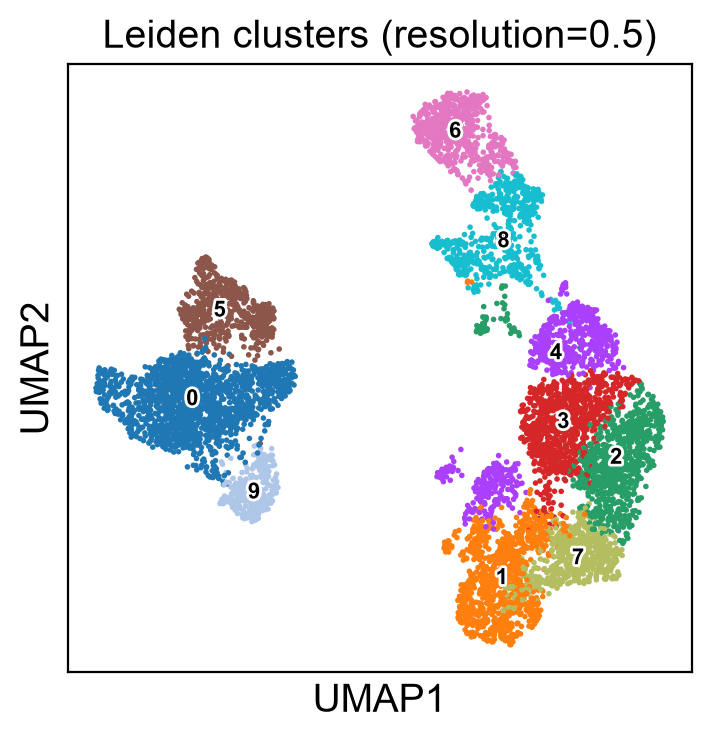

In [8]:
sc.pl.umap(adata, color='leiden', legend_loc='on data', legend_fontsize=8,
           legend_fontoutline=2, title=f'Leiden clusters (resolution={LEIDEN_RESOLUTION})')

## Step 3 — Write out preprocessed data

In [9]:
out_path = f"{PROCESSED_DIR}/preprocessed.h5ad"
adata.write_h5ad(out_path)
print(f"Saved: {out_path}")
print(f"  {adata.n_obs} cells  x  {adata.n_vars} genes")

Saved: /Users/adaml9/besca_sc/data/processed/preprocessed.h5ad
  7421 cells  x  32360 genes
